In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import seaborn as sns
from matplotlib.ticker import MaxNLocator
import warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",   # Prefer if installed
        "Liberation Serif",  # Common on Ubuntu / Debian
        "Nimbus Roman",      # Common with TeX / Ghostscript
        "DejaVu Serif"       # Matplotlib fallback
    ],
    "mathtext.fontset": "stix",       # Math symbols closer to Times
    "axes.unicode_minus": False,
})

import os
import sys
from pathlib import Path

# Utils lives under SynEnergy/. This notebook is Analysis/Figure/Motivation/
# Prefer the notebook file path (Cursor/VS Code); fall back to cwd.
_nb_file = globals().get("__vsc_ipynb_file__")
_nb_dir = Path(_nb_file).resolve().parent if _nb_file else Path.cwd().resolve()
synenergy_root = (_nb_dir / ".." / ".." / ".." / "SynEnergy").resolve()
if not (synenergy_root / "Utils").is_dir():
    # cwd may already be SysEnergy (or another parent)
    synenergy_root = None
    for p in [_nb_dir, *_nb_dir.parents]:
        cand = p / "SynEnergy"
        if (cand / "Utils").is_dir():
            synenergy_root = cand
            break
if synenergy_root is None:
    raise RuntimeError(f"Cannot locate SynEnergy/Utils from nb_dir={_nb_dir}, cwd={Path.cwd()}")
if str(synenergy_root) not in sys.path:
    sys.path.insert(0, str(synenergy_root))

import torch
from Utils.context_fid import Context_FID
from Utils.predictive_metric import predictive_score_metrics
import Utils.extreme_anomaly_metric as extreme_anomaly_metric
from Utils.extreme_anomaly_metric import (
    extreme_anomaly_score_metrics,
    extreme_reconstruction_score_metrics,
)


pd.set_option("display.max_rows", None)         # Show all rows
pd.set_option("display.max_columns", None)      # Show all columns
pd.set_option("display.width", None)            # No fixed-width wrap
pd.set_option("display.max_colwidth", None)     # Do not truncate cell values
pd.set_option("display.expand_frame_repr", False)  # Prefer single-line frames

PLOT_DIR = "../../../Analysis/Plot/Experiment/Anomaly_Visualization"

In [2]:
OUT = "../../../SynEnergy/OUTPUT/power"

ori = np.load(f"../../../SynEnergy/Data/Power/Tallahassee_seq_180_sample_10000.npy")
gen14 = np.load(f"{OUT}/heavydiffcontrol/power_heavy_controlnet1/generate_data_unnorm_power_heavy_controlnet1.npy")
gen24 = np.load(f"{OUT}/heavydiffcontrol/power_heavy_controlnet2/generate_data_unnorm_power_heavy_controlnet2.npy")
gen34 = np.load(f"{OUT}/heavydiffcontrol/power_heavy_controlnet3/generate_data_unnorm_power_heavy_controlnet3.npy")
gen44 = np.load(f"{OUT}/heavydiffcontrol/power_heavy_controlnet4/generate_data_unnorm_power_heavy_controlnet4.npy")
gen54 = np.load(f"{OUT}/heavydiffcontrol/power_heavy_controlnet5/generate_data_unnorm_power_heavy_controlnet5.npy")

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# --------- font size knobs ----------
FS_LABEL = 25
FS_TICK = 22
FS_LEGEND = 20
# ------------------------------------


def plot_random_samples_with_mean(
    gen14,
    ori=None,
    n_samples=1000,
    random_state=42,
    figsize=(5, 4.2),
    save_path=None,
    ylim=(0, 50),
    color="#AFCBFF",
    ori_color="#2166AC",
    loc="upper right",
    xlabel="Date (October 2018)",
    show_std_band=True,
):
    """
    Randomly select sequences from gen14 and visualize them
    with many thin colored lines + one mean curve.

    Parameters
    ----------
    gen14 : np.ndarray
        Input array with shape (N, T, 1) or (N, T)
    ori : np.ndarray or None
        Original data array with shape (N, T, 1) or (N, T). If provided,
        its mean sequence is drawn as a blue reference line.
    n_samples : int
        Number of randomly selected sequences
    random_state : int
        Random seed
    figsize : tuple
        Figure size
    save_path : str or None
        Save path
    show_std_band : bool
        Whether to draw mean ± std band
    """

    data = np.asarray(gen14)

    # (N, T, 1) -> (N, T)
    if data.ndim == 3 and data.shape[-1] == 1:
        data = data.squeeze(-1)

    if data.ndim != 2:
        raise ValueError(
            f"Expected shape (N, T, 1) or (N, T), but got {data.shape}."
        )

    N, T = data.shape
    n_samples = min(n_samples, N)

    rng = np.random.default_rng(random_state)
    idx = rng.choice(N, size=n_samples, replace=False)
    sampled = data[idx]

    tt = np.arange(T)

    # mean/std based on sampled sequences
    mu = sampled.mean(axis=0)
    sd = sampled.std(axis=0)

    fig, ax = plt.subplots(figsize=figsize)

    # colorful thin lines
    cmap = plt.colormaps["Spectral"]
    colors = cmap(np.linspace(0.05, 0.95, n_samples))

    for seq, c in zip(sampled, colors):
        ax.plot(
            tt,
            seq,
            color=c,
            alpha=0.15,
            linewidth=1.0,
            zorder=1,
        )

    # std band (do not include in legend)
    if show_std_band:
        ax.fill_between(
            tt,
            mu - sd,
            mu + sd,
            color="#AFCBFF",
            alpha=0.18,
            linewidth=0,
            zorder=2,
        )

    mean_linewidth = 2.6

    # mean line of sampled generated sequences
    ax.plot(
        tt,
        mu,
        color=color,
        linewidth=mean_linewidth,
        label="Average Generated Electricity Sequence",
        zorder=3,
    )

    if ori is not None:
        ori_data = np.asarray(ori)
        if ori_data.ndim == 3 and ori_data.shape[-1] == 1:
            ori_data = ori_data.squeeze(-1)
        if ori_data.ndim != 2:
            raise ValueError(
                f"Expected ori shape (N, T, 1) or (N, T), but got {ori_data.shape}."
            )
        if ori_data.shape[1] != T:
            raise ValueError(
                f"ori time length {ori_data.shape[1]} does not match gen14 length {T}."
            )

        mu_ori = ori_data.mean(axis=0)
        ax.plot(
            tt,
            mu_ori,
            color=ori_color,
            linewidth=mean_linewidth,
            label="Average Original Electricity Sequence",
            zorder=2,
        )

    ax.set_ylabel("Load(kWh)", fontsize=FS_LABEL)
    ax.set_xlabel(xlabel, fontsize=FS_LABEL)

    ax.tick_params(axis="both", labelsize=FS_TICK)
    ax.set_xlim(0, T - 1)
    ax.set_ylim(ylim)

    # custom time-axis ticks
    tick_positions = [0, 54, 114, 174]
    tick_labels = ["Oct 01", "Oct 10", "Oct 20", "Oct 30"]
    ax.set_xticks(tick_positions)
    ax.set_xticklabels(tick_labels, fontsize=FS_TICK)

    ax.legend(
        fontsize=FS_LEGEND,
        loc=loc,
        frameon=True,
    )

    fig.tight_layout()

    if save_path is not None:
        fig.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
            pad_inches=0.05,
        )

    plt.show()

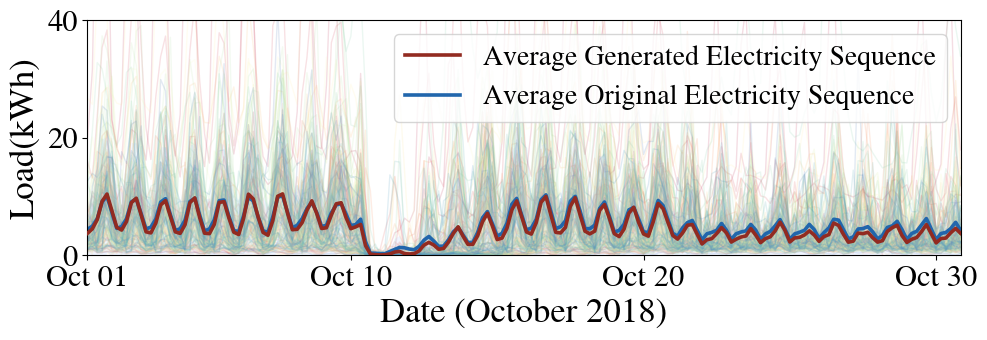

In [4]:
PLOT_DIR = "../../../Analysis/Plot/Experiment/Large_scale_Anomaly_Visualization"
plot_random_samples_with_mean(
    gen14,
    ori=ori,
    n_samples=200,
    random_state=618,
    figsize=(10, 3.5),
    color="#922B21",
    ylim=(0, 40),
    loc="upper right",
    show_std_band=True,
    save_path=f"{PLOT_DIR}/FL1.png",
)

In [5]:
OUT = "../../../SynEnergy/OUTPUT/power1"
ori = np.load(f"../../../SynEnergy/Data/Power/Tallahassee1_seq_180_sample_10000.npy")

gen14 = np.load(f"{OUT}/power1_heavy_controlnet1/generate_data_unnorm_power1_heavy_controlnet1.npy")
gen24 = np.load(f"{OUT}/power1_heavy_controlnet2/generate_data_unnorm_power1_heavy_controlnet2.npy")
gen34 = np.load(f"{OUT}/power1_heavy_controlnet3/generate_data_unnorm_power1_heavy_controlnet3.npy")

In [6]:
gen14.shape

(10000, 180, 1)

In [7]:
import numpy as np


def select_top_heatwave_households(
    gen14,
    gen24,
    gen34,
    top_k=1000,
):
    """
    从三个五月电力数据集中，选出 5 月 23–29 日期间
    相较于 5 月 1–22 日平均用电提升最大的 top_k 个家庭。

    Parameters
    ----------
    gen14, gen24, gen34 : np.ndarray
        Shape 均为 (10000, 180, 1)。
        每个时间步为 4 小时，每天 6 个时间步。
    top_k : int
        需要选择的家庭数量。

    Returns
    -------
    gen : np.ndarray
        选出的家庭完整月度序列，shape 为 (top_k, 180, 1)。
    top_indices : np.ndarray
        这些家庭在拼接后 30000 条序列中的索引。
    increase_scores : np.ndarray
        对应家庭的热浪期平均用电提升量。
    source_ids : np.ndarray
        家庭来自哪个数据集：
        0 表示 gen14，1 表示 gen24，2 表示 gen34。
    local_indices : np.ndarray
        家庭在原始数据集内部的索引。
    """

    arrays = [
        np.asarray(gen14),
        np.asarray(gen24),
        np.asarray(gen34),
    ]

    # 检查数据维度
    for name, arr in zip(
        ["gen14", "gen24", "gen34"],
        arrays,
    ):
        if arr.ndim != 3 or arr.shape[1:] != (180, 1):
            raise ValueError(
                f"{name} should have shape (N, 180, 1), "
                f"but got {arr.shape}."
            )

    # 合并为 (30000, 180, 1)
    all_gen = np.concatenate(arrays, axis=0)

    n_total = all_gen.shape[0]
    top_k = min(top_k, n_total)

    # 去掉最后一个单变量维度，得到 (30000, 180)
    data = all_gen[:, :, 0]

    steps_per_day = 6

    # May 1–22：索引 [0, 132)
    baseline_start = 0
    baseline_end = (23 - 1) * steps_per_day  # 132

    # May 23–29：索引 [132, 174)
    heatwave_start = (23 - 1) * steps_per_day  # 132
    heatwave_end = 29 * steps_per_day          # 174

    # 每个家庭在热浪前和热浪期间的平均用电
    baseline_mean = np.nanmean(
        data[:, baseline_start:baseline_end],
        axis=1,
    )

    heatwave_mean = np.nanmean(
        data[:, heatwave_start:heatwave_end],
        axis=1,
    )

    # 绝对提升量
    increase = heatwave_mean - baseline_mean

    # 排除无法计算得分的样本
    valid = np.isfinite(increase)
    valid_indices = np.flatnonzero(valid)

    if valid_indices.size < top_k:
        raise ValueError(
            f"Only {valid_indices.size} sequences have valid scores, "
            f"which is fewer than top_k={top_k}."
        )

    valid_scores = increase[valid]

    # 先快速找到最大的 top_k 个，再按得分降序排列
    candidate_pos = np.argpartition(
        valid_scores,
        -top_k,
    )[-top_k:]

    candidate_indices = valid_indices[candidate_pos]

    order = np.argsort(
        increase[candidate_indices]
    )[::-1]

    top_indices = candidate_indices[order]

    # 新的 gen，保留完整的 180 个时间步
    gen = all_gen[top_indices].copy()

    increase_scores = increase[top_indices]

    # 确定每条序列来自哪个数据集
    dataset_sizes = np.array([arr.shape[0] for arr in arrays])
    boundaries = np.cumsum(dataset_sizes)

    source_ids = np.searchsorted(
        boundaries,
        top_indices,
        side="right",
    )

    starts = np.concatenate(([0], boundaries[:-1]))
    local_indices = top_indices - starts[source_ids]

    return (
        gen,
        top_indices,
        increase_scores,
        source_ids,
        local_indices,
    )

In [8]:
gen, top_indices, increase_scores, source_ids, local_indices = (
    select_top_heatwave_households(
        gen14,
        gen24,
        gen34,
        top_k=1000,
    )
)
gen = gen-5
gen = gen/2.5


gen1, top_indices, increase_scores, source_ids, local_indices = (
    select_top_heatwave_households(
        gen14,
        gen24,
        gen34,
        top_k=1800,
    )
)
gen1 = gen1-5
gen1 = gen1/2.5

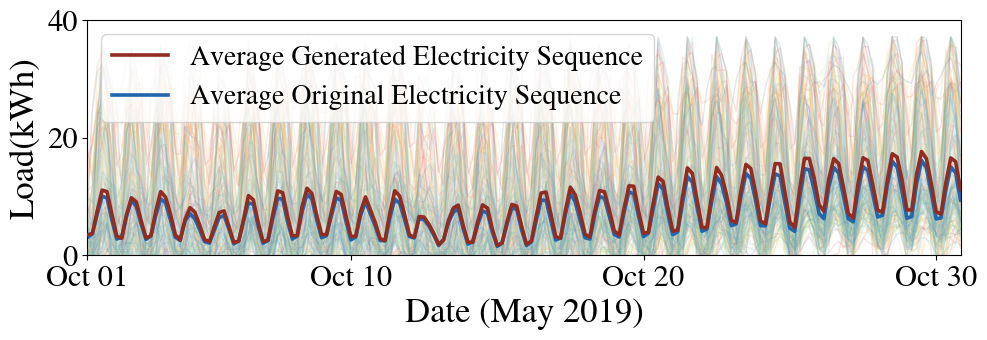

In [11]:
PLOT_DIR = "../../../Analysis/Plot/Experiment/Large_scale_Anomaly_Visualization"
plot_random_samples_with_mean(
    gen,
    ori=gen1,
    n_samples=200,
    random_state=618,
    figsize=(10, 3.5),
    color="#922B21",
    ylim=(0, 40),
    show_std_band=True,
    loc="upper left",
    xlabel="Date (May 2019)",
    save_path=f"{PLOT_DIR}/FL2.png",
)